In [1]:
!git clone https://github.com/sonia250/hmm-activity-recognition.git
%cd hmm-activity-recognition

Cloning into 'hmm-activity-recognition'...
remote: Enumerating objects: 76, done.
remote: Counting objects: 100% (76/76), done.
remote: Compressing objects: 100% (75/75), done.
remote: Total 76 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (76/76), 1.45 MiB | 3.80 MiB/s, done.
/content/hmm-activity-recognition


In [2]:
import glob, os, re
import numpy as np
import pandas as pd

FS = 50                  # sampling rate (Hz)
WIN_SEC = 2.0            # window length in seconds
WIN = int(WIN_SEC * FS)  # 100 samples
STEP = WIN // 2          # 50% overlap
ACTIVITIES = ["standing", "walking", "jumping", "still"]

In [3]:
EPS = 1e-6   # avoids log(0)

def sma(xyz):
    """Signal magnitude area: mean of |x|+|y|+|z|."""
    return np.mean(np.sum(np.abs(xyz), axis=1))

def axis_corr(xyz):
    """Mean absolute correlation between the three axes."""
    c = np.corrcoef(xyz.T)
    c = np.nan_to_num(c)
    return np.mean(np.abs([c[0, 1], c[0, 2], c[1, 2]]))

def fft_features(sig, fs=FS):
    """Dominant frequency (Hz) and spectral energy of a 1-D signal."""
    sig = sig - sig.mean()
    spec = np.abs(np.fft.rfft(sig))
    freqs = np.fft.rfftfreq(len(sig), d=1 / fs)
    dom = freqs[1:][np.argmax(spec[1:])]
    energy = np.sum(spec[1:] ** 2) / len(sig)
    return dom, energy

def window_features(w):
    """w: (WIN, 6) array = acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z."""
    feats = {}
    for name, xyz in (("acc", w[:, :3]), ("gyro", w[:, 3:])):
        mag = np.linalg.norm(xyz, axis=1)
        dom, energy = fft_features(mag)
        # "Size" features span orders of magnitude, so we take the log
        feats[f"{name}_mean"] = np.log(mag.mean() + EPS)
        feats[f"{name}_std"] = np.log(mag.std() + EPS)
        feats[f"{name}_rms"] = np.log(np.sqrt(np.mean(mag ** 2)) + EPS)
        feats[f"{name}_sma"] = np.log(sma(xyz) + EPS)
        feats[f"{name}_corr"] = axis_corr(xyz)
        feats[f"{name}_domfreq"] = dom
        feats[f"{name}_energy"] = np.log(energy + EPS)
    return feats

In [4]:
cols = ["acc_x", "acc_y", "acc_z", "gyro_x", "gyro_y", "gyro_z"]

def build_table(split):
    rows = []
    for path in sorted(glob.glob(f"data/{split}/*.csv")):
        name = os.path.basename(path)
        activity = re.match(r"^(\w+?)_", name).group(1)
        data = pd.read_csv(path)[cols].values
        for k, start in enumerate(range(0, len(data) - WIN + 1, STEP)):
            f = window_features(data[start:start + WIN])
            f.update(file=name, activity=activity, win=k)
            rows.append(f)
    return pd.DataFrame(rows)

train = build_table("train")
test = build_table("test")
feat_cols = [c for c in train.columns if c not in ("file", "activity", "win")]
print("train windows:", len(train), " test windows:", len(test))
print(train.groupby("activity").size())

train windows: 364  test windows: 56
activity
jumping     94
standing    90
still       90
walking     90
dtype: int64


In [5]:
mu, sd = train[feat_cols].mean(), train[feat_cols].std().replace(0, 1)
train_z, test_z = train.copy(), test.copy()
train_z[feat_cols] = (train[feat_cols] - mu) / sd
test_z[feat_cols] = (test[feat_cols] - mu) / sd

os.makedirs("features", exist_ok=True)
train_z.to_csv("features/train_features_z.csv", index=False)
test_z.to_csv("features/test_features_z.csv", index=False)
print("saved")

saved


In [6]:
print(train.groupby("activity")[feat_cols].mean().loc[ACTIVITIES].round(3).T)

activity      standing  walking  jumping  still
acc_mean        -2.555    0.218    2.319 -3.470
acc_std         -3.326   -0.710    1.744 -5.039
acc_rms         -2.453    0.294    2.458 -3.394
acc_sma         -2.151    0.594    2.554 -3.108
acc_corr         0.258    0.210    0.537  0.143
acc_domfreq      2.339    1.822    4.106  6.122
acc_energy      -2.740    2.493    7.400 -6.158
gyro_mean       -3.443   -0.567    0.071 -6.178
gyro_std        -4.151   -1.294   -0.703 -6.820
gyro_rms        -3.322   -0.458    0.171 -6.006
gyro_sma        -3.041   -0.188    0.459 -5.788
gyro_corr        0.238    0.236    0.258  0.129
gyro_domfreq     1.794    1.072    2.755  6.039
gyro_energy     -4.389    1.324    2.507 -9.695


In [7]:
import matplotlib.pyplot as plt
from collections import Counter

train_z = pd.read_csv("features/train_features_z.csv")
test_z = pd.read_csv("features/test_features_z.csv")
feat_cols = [c for c in train_z.columns if c not in ("file", "activity", "win")]

def make_sequences(df):
    """One sequence per file: windows in time order, plus true labels (0-3)."""
    seqs, labels, names = [], [], []
    for fname, g in df.groupby("file", sort=True):
        g = g.sort_values("win")
        seqs.append(g[feat_cols].values)
        labels.append([ACTIVITIES.index(a) for a in g["activity"]])
        names.append(fname)
    return seqs, labels, names

tr_seqs, tr_labels, tr_names = make_sequences(train_z)
te_seqs, te_labels, te_names = make_sequences(test_z)
print("training sequences:", len(tr_seqs), " test sequences:", len(te_seqs))
print("features per window:", len(feat_cols))

training sequences: 53  test sequences: 8
features per window: 14


In [8]:
def logsumexp(a, axis=None):
    """Stable log(sum(exp(a)))."""
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    out = np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True)) + m
    return float(out.squeeze()) if axis is None else np.squeeze(out, axis=axis)

class GaussianHMM:
    """HMM with Gaussian (diagonal covariance) emissions, written with numpy only.
    pi = initial probabilities, A = transitions, means/vars = emissions (B)."""

    def __init__(self, n_states, n_features, var_floor=1e-2):
        self.N, self.D, self.var_floor = n_states, n_features, var_floor

    def init_from_labels(self, seqs, labels, smoothing=1e-2):
        """Starting values: one state per activity, from the labelled windows."""
        self.means = np.zeros((self.N, self.D))
        self.vars = np.ones((self.N, self.D))
        for s in range(self.N):
            Xs = np.vstack([X[np.array(l) == s] for X, l in zip(seqs, labels)])
            self.means[s] = Xs.mean(axis=0)
            self.vars[s] = Xs.var(axis=0) + self.var_floor
        A = np.full((self.N, self.N), smoothing)
        pi = np.full(self.N, smoothing)
        for l in labels:
            pi[l[0]] += 1
            for a, b in zip(l[:-1], l[1:]):
                A[a, b] += 1
        self.A = A / A.sum(axis=1, keepdims=True)
        self.pi = pi / pi.sum()

    def log_emission(self, X):
        """log P(x_t | state) for every window and state -> (T, N)."""
        diff = X[:, None, :] - self.means[None]
        return -0.5 * np.sum(np.log(2 * np.pi * self.vars)[None]
                             + diff ** 2 / self.vars[None], axis=2)

    def forward_backward(self, X):
        """Returns gamma (state probs), xi (transition counts), log-likelihood."""
        T = len(X)
        logB, logA, logpi = self.log_emission(X), np.log(self.A), np.log(self.pi)
        alpha = np.zeros((T, self.N))
        beta = np.zeros((T, self.N))
        alpha[0] = logpi + logB[0]
        for t in range(1, T):
            alpha[t] = logsumexp(alpha[t - 1][:, None] + logA, axis=0) + logB[t]
        for t in range(T - 2, -1, -1):
            beta[t] = logsumexp(logA + (logB[t + 1] + beta[t + 1])[None], axis=1)
        loglik = logsumexp(alpha[-1])
        gamma = np.exp(alpha + beta - loglik)
        xi = np.zeros((self.N, self.N))
        for t in range(T - 1):
            xi += np.exp(alpha[t][:, None] + logA
                         + (logB[t + 1] + beta[t + 1])[None] - loglik)
        return gamma, xi, loglik

    def fit(self, seqs, max_iter=200, tol=1e-4):
        """Baum-Welch (EM). Stops when the log-likelihood changes by less than
        tol (relative) between two iterations."""
        history = []
        for it in range(1, max_iter + 1):
            G0 = np.zeros(self.N)
            XI = np.zeros((self.N, self.N))
            Gs = np.zeros(self.N)
            GX = np.zeros((self.N, self.D))
            GXX = np.zeros((self.N, self.D))
            total = 0.0
            for X in seqs:                                  # E-step
                gamma, xi, ll = self.forward_backward(X)
                total += ll
                G0 += gamma[0]
                XI += xi
                Gs += gamma.sum(axis=0)
                GX += gamma.T @ X
                GXX += gamma.T @ (X ** 2)
            self.pi = (G0 + 1e-6) / (G0 + 1e-6).sum()       # M-step
            self.A = (XI + 1e-6) / (XI + 1e-6).sum(axis=1, keepdims=True)
            self.means = GX / Gs[:, None]
            self.vars = np.maximum(GXX / Gs[:, None] - self.means ** 2, 0) + self.var_floor
            history.append(total)
            if it == 1 or it % 5 == 0:
                print(f"iteration {it:3d}   log-likelihood = {total:.3f}")
            if it > 1 and abs(history[-1] - history[-2]) < tol * abs(history[-2]):
                print(f"Converged at iteration {it} (change < {tol} of the log-likelihood)")
                break
        return history

    def viterbi(self, X):
        """Most likely state sequence for X."""
        T = len(X)
        logB, logA, logpi = self.log_emission(X), np.log(self.A), np.log(self.pi)
        delta = np.zeros((T, self.N))
        psi = np.zeros((T, self.N), dtype=int)
        delta[0] = logpi + logB[0]
        for t in range(1, T):
            scores = delta[t - 1][:, None] + logA
            psi[t] = np.argmax(scores, axis=0)
            delta[t] = scores[psi[t], np.arange(self.N)] + logB[t]
        path = np.zeros(T, dtype=int)
        path[-1] = np.argmax(delta[-1])
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1, path[t + 1]]
        return path

In [9]:
hmm = GaussianHMM(n_states=4, n_features=len(feat_cols))
hmm.init_from_labels(tr_seqs, tr_labels)
history = hmm.fit(tr_seqs)

iteration   1   log-likelihood = 175.370
iteration   5   log-likelihood = 695.411
Converged at iteration 6 (change < 0.0001 of the log-likelihood)


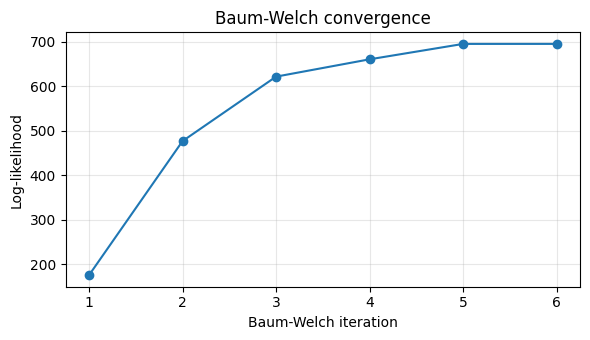

In [10]:
plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(history) + 1), history, marker="o")
plt.xlabel("Baum-Welch iteration")
plt.ylabel("Log-likelihood")
plt.title("Baum-Welch convergence")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("convergence.png", dpi=150)
plt.show()

In [11]:
votes = {s: Counter() for s in range(4)}
for X, l in zip(tr_seqs, tr_labels):
    for pred, true in zip(hmm.viterbi(X), l):
        votes[pred][true] += 1
state_to_activity = {s: votes[s].most_common(1)[0][0] for s in range(4)}
print({s: ACTIVITIES[a] for s, a in state_to_activity.items()})

def decode(X):
    """Viterbi path converted to activity numbers."""
    return np.array([state_to_activity[s] for s in hmm.viterbi(X)])

correct = sum((decode(X) == np.array(l)).sum() for X, l in zip(tr_seqs, tr_labels))
total = sum(len(l) for l in tr_labels)
print(f"Training accuracy: {correct / total:.3f}")
print("Transition matrix A (rows = from, columns = to):")
print(pd.DataFrame(hmm.A, index=ACTIVITIES, columns=ACTIVITIES).round(3))

{0: 'standing', 1: 'walking', 2: 'jumping', 3: 'still'}
Training accuracy: 0.967
Transition matrix A (rows = from, columns = to):
          standing  walking  jumping  still
standing     0.943      0.0      0.0  0.057
walking      0.000      1.0      0.0  0.000
jumping      0.000      0.0      1.0  0.000
still        0.061      0.0      0.0  0.939


In [12]:
y_true, y_pred = [], []
for X, l in zip(te_seqs, te_labels):
    y_true += list(l)
    y_pred += list(decode(X))
y_true, y_pred = np.array(y_true), np.array(y_pred)

conf = np.zeros((4, 4), dtype=int)           # rows = true, columns = predicted
for t, p in zip(y_true, y_pred):
    conf[t, p] += 1

total = conf.sum()
rows = []
for i, name in enumerate(ACTIVITIES):
    TP = conf[i, i]
    FN = conf[i].sum() - TP
    FP = conf[:, i].sum() - TP
    TN = total - TP - FN - FP
    rows.append({
        "State (Activity)": name,
        "Number of Samples": int(conf[i].sum()),
        "Sensitivity": round(TP / (TP + FN), 3),
        "Specificity": round(TN / (TN + FP), 3),
        "Overall Accuracy": round((TP + TN) / total, 3),
    })
results = pd.DataFrame(rows)
print(results.to_string(index=False))
print(f"\nOverall accuracy on the test data: {np.trace(conf) / total:.3f}  ({total} windows)")

State (Activity)  Number of Samples  Sensitivity  Specificity  Overall Accuracy
        standing                 14          1.0          1.0               1.0
         walking                 14          1.0          1.0               1.0
         jumping                 14          1.0          1.0               1.0
           still                 14          1.0          1.0               1.0

Overall accuracy on the test data: 1.000  (56 windows)


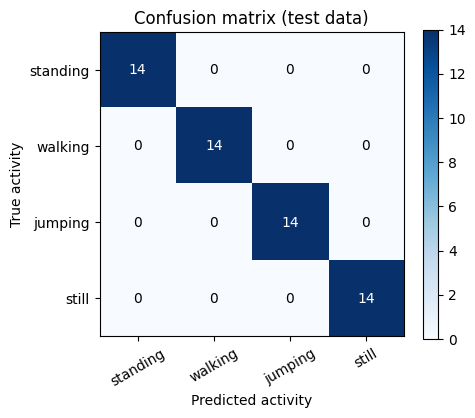

In [13]:
fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(conf, cmap="Blues")
ax.set_xticks(range(4)); ax.set_xticklabels(ACTIVITIES, rotation=30)
ax.set_yticks(range(4)); ax.set_yticklabels(ACTIVITIES)
ax.set_xlabel("Predicted activity"); ax.set_ylabel("True activity")
ax.set_title("Confusion matrix (test data)")
for i in range(4):
    for j in range(4):
        ax.text(j, i, conf[i, j], ha="center", va="center",
                color="white" if conf[i, j] > conf.max() / 2 else "black")
plt.colorbar(im)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

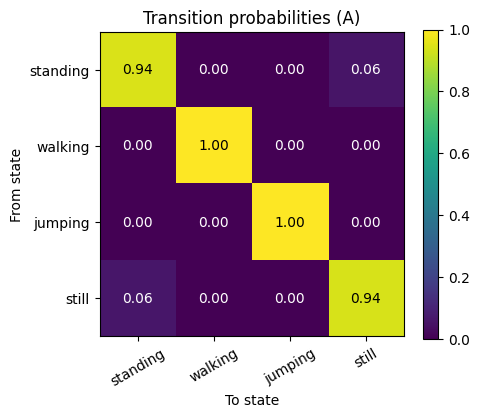

In [14]:
fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(hmm.A, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels(ACTIVITIES, rotation=30)
ax.set_yticks(range(4)); ax.set_yticklabels(ACTIVITIES)
ax.set_xlabel("To state"); ax.set_ylabel("From state")
ax.set_title("Transition probabilities (A)")
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{hmm.A[i, j]:.2f}", ha="center", va="center",
                color="white" if hmm.A[i, j] < 0.6 else "black")
plt.colorbar(im)
plt.tight_layout()
plt.savefig("transition_heatmap.png", dpi=150)
plt.show()

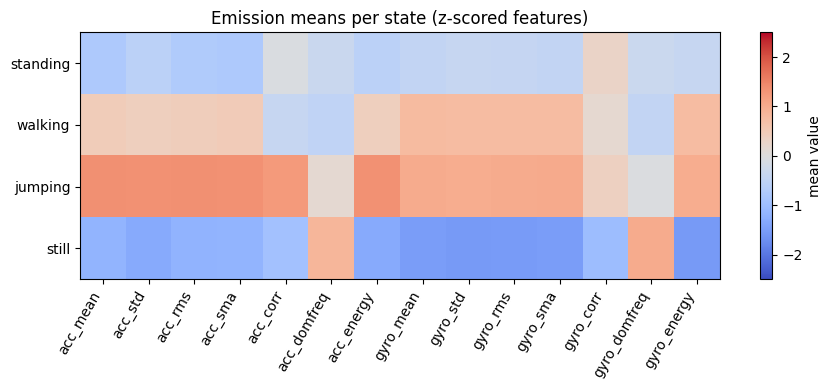

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(hmm.means, cmap="coolwarm", aspect="auto", vmin=-2.5, vmax=2.5)
ax.set_yticks(range(4)); ax.set_yticklabels([ACTIVITIES[state_to_activity[s]] for s in range(4)])
ax.set_xticks(range(len(feat_cols))); ax.set_xticklabels(feat_cols, rotation=60, ha="right")
ax.set_title("Emission means per state (z-scored features)")
plt.colorbar(im, label="mean value")
plt.tight_layout()
plt.savefig("emission_means.png", dpi=150)
plt.show()

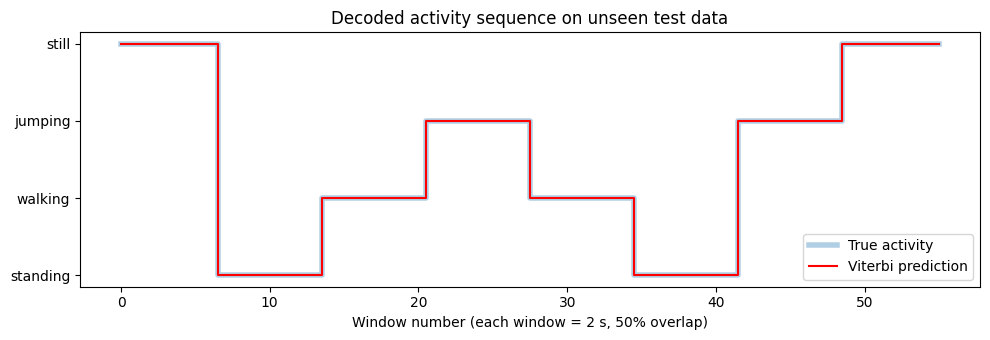

Accuracy on this joined sequence: 1.0


In [16]:
order = ["still_test_1_01", "standing_test_1_01", "walking_test_1_01", "jumping_test_1_01",
         "walking_test_1_02", "standing_test_1_02", "jumping_test_1_02", "still_test_1_02"]
X_all, true_all = [], []
for name in order:
    k = te_names.index(name + ".csv")
    X_all.append(te_seqs[k]); true_all += list(te_labels[k])
X_all, true_all = np.vstack(X_all), np.array(true_all)
pred_all = decode(X_all)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.step(range(len(true_all)), true_all, where="mid", label="True activity", lw=4, alpha=0.35)
ax.step(range(len(pred_all)), pred_all, where="mid", label="Viterbi prediction", lw=1.5, color="red")
ax.set_yticks(range(4)); ax.set_yticklabels(ACTIVITIES)
ax.set_xlabel("Window number (each window = 2 s, 50% overlap)")
ax.set_title("Decoded activity sequence on unseen test data")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("decoded_sequence.png", dpi=150)
plt.show()
print("Accuracy on this joined sequence:", (pred_all == true_all).mean().round(3))

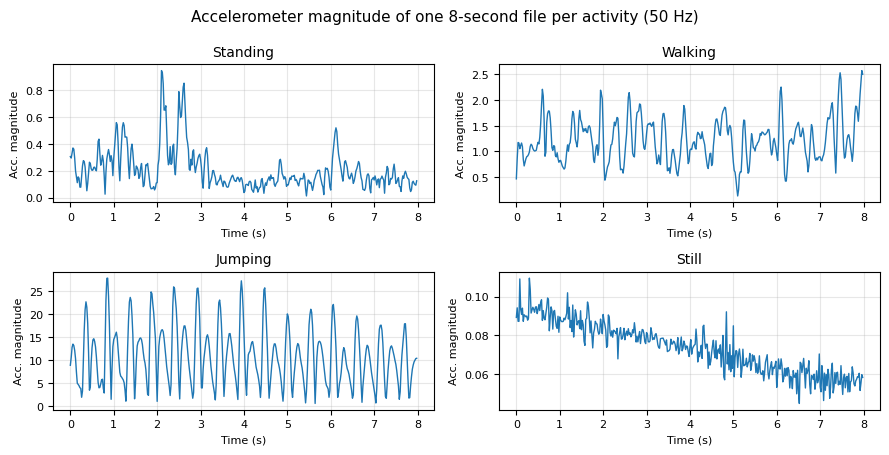

In [17]:
import glob
fig, axes = plt.subplots(2, 2, figsize=(9, 4.6))
for ax, act in zip(axes.ravel(), ACTIVITIES):
    path = sorted(glob.glob(f"data/train/{act}_train_*.csv"))[0]
    d = pd.read_csv(path)
    mag = np.sqrt(d.acc_x**2 + d.acc_y**2 + d.acc_z**2)
    ax.plot(d.time_s, mag, lw=1)
    ax.set_title(act.capitalize(), fontsize=10)
    ax.set_xlabel("Time (s)", fontsize=8); ax.set_ylabel("Acc. magnitude", fontsize=8)
    ax.tick_params(labelsize=8); ax.grid(alpha=0.3)
plt.suptitle("Accelerometer magnitude of one 8-second file per activity (50 Hz)", fontsize=11)
plt.tight_layout()
plt.savefig("sample_signals.png", dpi=150)
plt.show()